# Pré-traitements de textes, comptages et loi de Zipf

- Recherche de motifs via expressions régulières
- Récupération et pré-traitements de corpus libres de droits (segmentation en phrases et en tokens)
- Comptages d'occurrences et vérification de la loi de Zipf

**Copiez ce notebook et mettez votre nom dans le nom de la copie**

M'envoyer le lien (avec droits d'édition) vers votre colab par mail marie.candito@gmail.com, avant le **mercredi 14 janvier minuit**, avec comme objet du mail :  **MIDS TP1**

**Attention**: je ne prends pas en compte les mails qui n'ont pas cet objet!

**NB: Ne pas m'envoyer** de notebook.

## Outil : les expressions régulières

Une expression régulière ("regular expression" ou regexp) représente un ensemble de chaînes de caractères. Par exemple 'a*' représente l'ensemble {'', 'a', 'aa', 'aaa', 'aaaa', ...}. La regexp 'ab+' représente toutes les chaînes formées d'un a suivi de 1 ou plusieurs b ({'ab', 'abb', 'abbb', ...}).

Les langages informatiques permettent de rechercher dans une chaîne de caractères l'ensemble des sous-parties qui "matchent" une expression régulière.

Par exemple dans la chaîne "abbcacabaaabbb", la regexp 'ab+' a 3 matchs.

En TAL, on peut à l'aide de regexp réaliser la segmentation d'un texte, ou bien rechercher des dates, des URLs, des noms propres...

En python, on peut utiliser les regex à l'aide de la librairie `re`

In [1]:
import re

sample_text = """
    Bonjour, je m'appelle Sam. Mon numéro de téléphone est le 04.56.55.33.66
    Super, je suis M. Max. Mon numéro est le 0392020302
    Génial, je vous donne également mon tel : 03-02-02-12-89 et celui du bureau : +33 (0) 5 33 19 33 09.
    Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ?
    Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone.
"""

Par exemple, on peut chercher un chiffre dans le texte:

In [2]:
digits = re.findall(r'[0-9]', sample_text)
print(digits)

digits2 = re.findall(r'\d', sample_text)
print(digits2)

['0', '4', '5', '6', '5', '5', '3', '3', '6', '6', '0', '3', '9', '2', '0', '2', '0', '3', '0', '2', '0', '3', '0', '2', '0', '2', '1', '2', '8', '9', '3', '3', '0', '5', '3', '3', '1', '9', '3', '3', '0', '9', '0', '6', '1', '2', '2', '0', '1', '3', '1', '2', '3', '4', '5', '6', '7', '8', '9', '9', '9']
['0', '4', '5', '6', '5', '5', '3', '3', '6', '6', '0', '3', '9', '2', '0', '2', '0', '3', '0', '2', '0', '3', '0', '2', '0', '2', '1', '2', '8', '9', '3', '3', '0', '5', '3', '3', '1', '9', '3', '3', '0', '9', '0', '6', '1', '2', '2', '0', '1', '3', '1', '2', '3', '4', '5', '6', '7', '8', '9', '9', '9']


Ou deux chiffres qui se suivent:

In [3]:
digits = re.findall(r'\d{2}', sample_text)
print(digits)

['04', '56', '55', '33', '66', '03', '92', '02', '03', '02', '03', '02', '02', '12', '89', '33', '33', '19', '33', '09', '06', '12', '20', '13', '12', '34', '56', '78', '99']


Finalement on peut chercher l'ensemble des occurrences formées d'une séquence d'un ou plusieurs chiffres qui se suivent.
NB: Notez qu'ici les matches les plus longs priment.

In [4]:
# on peut compiler une fois pour toute une regexp (intéressant si réutilisée souvent)
digit_pattern = re.compile(r'\d+')
# + pour matcher 1 fois ou plusieurs fois le caractère précédent
# * pour matcher 0 fois, 1 fois ou plusieurs fois le caractère précédent

digits = re.findall(digit_pattern, sample_text)
print(digits)

['04', '56', '55', '33', '66', '0392020302', '03', '02', '02', '12', '89', '33', '0', '5', '33', '19', '33', '09', '06', '12', '20', '13', '12345678999']


On peut utiliser des parenthèses pour indiquer la portée des quantifieurs.

In [24]:
# par exemple une séquence d'une ou plusieurs fois 2 chiffres plus un point
# NB: le "?:" indique que les parenthèses sont "non capturantes"
seq_of_pairs = re.findall(r'(?:[0-9]{2}\.)+', sample_text)
print(seq_of_pairs)

['04.56.55.33.', '09.']


On peut également chercher des groupes plus complexes, par exemple un numéro de téléphone

In [27]:
telephone_pattern = re.compile(r'(?:\d\d[ \.\n\-]){5}')
# on cherche 5 fois 2 chiffres suivis soit d'un point, soit d'un espace soit d'un retour à la ligne
# ([] est l'équivalent de "ou" pour l'ensemble des caractères au sein des crochets, ici espace ou point ou \n)

telephone = re.findall(telephone_pattern, sample_text)
print(telephone)

['04.56.55.33.66\n', '03-02-02-12-89 ']


La librairie `re` comprend également d'autres méthodes.

`re.match` ou `re.search` cherche le premier match (soit en début de chaîne, soit n'importe où) et rend un match object:

In [7]:
m = re.search(r'[0-9]{2}', sample_text)
print(m)

if m:
    print(m.group(0))

<re.Match object; span=(63, 65), match='04'>
04


La fonction `re.sub` qui permet de remplacer tous les matchs par une chaîne de caractères fixe. Un exemple ici pour anonymiser des données.

In [8]:
sample_text_anonymized = re.sub(telephone_pattern, ' XX.XX.XX.XX.XX ', sample_text)
print(sample_text_anonymized)


    Bonjour, je m'appelle Sam. Mon numéro de téléphone est le  XX.XX.XX.XX.XX     Super, je suis M. Max. Mon numéro est le 0392020302
    Génial, je vous donne également mon tel :  XX.XX.XX.XX.XX et celui du bureau : +33 (0) 5 33 19 33 09.
    Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ?
    Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone.



On peut également tronçonner une chaîne de caractères en décrivant le séparateur au moyen d'une regexp:

In [9]:
# attention, les séparateurs sont du coup supprimés
tokens = re.split(r'[ \.,\'\?\n]+', sample_text)
print(tokens)

['', 'Bonjour', 'je', 'm', 'appelle', 'Sam', 'Mon', 'numéro', 'de', 'téléphone', 'est', 'le', '04', '56', '55', '33', '66', 'Super', 'je', 'suis', 'M', 'Max', 'Mon', 'numéro', 'est', 'le', '0392020302', 'Génial', 'je', 'vous', 'donne', 'également', 'mon', 'tel', ':', '03-02-02-12-89', 'et', 'celui', 'du', 'bureau', ':', '+33', '(0)', '5', '33', '19', '33', '09', 'Est-ce', 'que', 'vous', 'seriez', 'disponible', 'pour', 'un', 'rendez', 'vous', 'le', '06/12/20', 'vers', '13h', 'Mon', 'identifiant', 'est', 'le', '12345678999', 'mais', 'ce', 'n', 'est', 'pas', 'un', 'numéro', 'de', 'téléphone', '']


On pourra s'appuyer sur l'outil : https://regex101.com/. Un autre excellent site pour s'entrainer aux expresions régulières : https://alf.nu/RegexGolf et une cheat sheet : https://cheatography.com/davechild/cheat-sheets/regular-expressions/


## TODO 1
Trouvez une regexp pour matcher tous les numéros de téléphone contenus dans le texte, **mais sans matcher l'identifiant**.

Pour cela vous pouvez utiliser les "lookahead" et "lookbehind" assertions, cf. https://docs.python.org/3/library/re.html


In [115]:
sample_text = """
    Bonjour, je m'appelle Sam. Mon numéro de téléphone est le 04.56.55.33.66
    Super, je suis M. Max. Mon numéro est le 0392020302
    Génial, je vous donne également mon tel : 03-02-02-12-89 et celui du bureau : +33 (0) 5 33 19 33 09.
    Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ?
    Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone.
"""

## Solution TODO 1

In [66]:
numeros_sample_test = re.compile(r'\d{10}(?=\n)|(?:\d{2}[ \n\.\-]){5}|(?:\+33 \(0\) 5 )(?:\d{2}[ \.]){4}')
telephones = re.findall(numeros_sample_test, sample_text)
print(telephones)

['04.56.55.33.66\n', '0392020302', '03-02-02-12-89 ', '+33 (0) 5 33 19 33 09.']


## Segmentation du texte en phrases

### TODO 2:
Décrivez le problème causé par la regex utilisée pour segmenter le `text` en phrases.

Modifiez la regex pour mieux matcher les frontières de phrase.

**Indications**: possibilité d'utiliser les "**lookbehind assertions**" https://docs.python.org/3/library/re.html pour contrôler sur quels séparateurs opérer le découpage.


In [126]:
# à modifier
sent_frontier_pattern = re.compile(r'(?<!M.)(?<=[.?])\s+(?=[A-Z])')

def split_into_sentences(text):
    sentences = re.split(sent_frontier_pattern, text)
    return sentences

for s in split_into_sentences(sample_text):
    print('<<', s, '\n')



<< 
    Bonjour, je m'appelle Sam. 

<< Mon numéro de téléphone est le 04.56.55.33.66
    Super, je suis M. Max. 

<< Mon numéro est le 0392020302
    Génial, je vous donne également mon tel : 03-02-02-12-89 et celui du bureau : +33 (0) 5 33 19 33 09. 

<< Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ? 

<< Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone.
 



## Solution TODO 2

Ici, le problème est lié à l’expression régulière qui définit la fin d’une phrase comme étant un point suivi d’un espace et d’une lettre majuscule. Or, la fonction split() supprime l’expression régulière après avoir tronqué la chaîne. Cela entraîne la disparition du point ainsi que de la première lettre de la phrase suivante, ce qui provoque une coupure incorrecte de certains mots.

Pour corriger cela, l’expression régulière doit utiliser des assertions de type lookbehind afin de détecter la frontière de phrase sans consommer les caractères de ponctuation. Une expression plus adaptée consiste à découper uniquement sur les espaces ou retours à la ligne qui suivent une véritable ponctuation de fin de phrase, tout en excluant les abréviations telles que « M. ». 

## Tokenisation avec nltk

`nltk` est une librairie de NLP à visée pédagogique.

In [122]:
import nltk
nltk.download('punkt_tab') # needed to use nltk.tokenize.sent_tokenize

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/fatoumata/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [124]:
# la segmentation en phrases peut se faire avec `sent_tokenize`, issu d'un apprentissage automatique
sentences = nltk.tokenize.sent_tokenize(sample_text)
print(sentences)

["\n    Bonjour, je m'appelle Sam.", 'Mon numéro de téléphone est le 04.56.55.33.66\n    Super, je suis M. Max.', 'Mon numéro est le 0392020302\n    Génial, je vous donne également mon tel : 03-02-02-12-89 et celui du bureau : +33 (0) 5 33 19 33 09.', 'Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ?', "Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone."]


In [125]:
# si on suppose que les retours à la ligne correspondent à des frontières de phrase
# (attention ce n'est pas toujours le cas)

def split_into_sentences(text):
    sent_lists = [nltk.tokenize.sent_tokenize(x) for x in text.split('\n')]
    return [sent.strip() for sent_list in sent_lists for sent in sent_list]

print(split_into_sentences(sample_text))

["Bonjour, je m'appelle Sam.", 'Mon numéro de téléphone est le 04.56.55.33.66', 'Super, je suis M. Max.', 'Mon numéro est le 0392020302', 'Génial, je vous donne également mon tel : 03-02-02-12-89 et celui du bureau : +33 (0) 5 33 19 33 09.', 'Est-ce que vous seriez disponible pour un rendez vous le 06/12/20 vers 13h ?', "Mon identifiant est le 12345678999 mais ce n'est pas un numéro de téléphone."]


### TODO3
La méthode `nltk.tokenize.word_tokenize` permet à la fois de segmenter en phrases et en tokens.
Utilisez-la et identifiez des problèmes.

In [128]:
sample2 = """Ceci est une phrase n'est-ce pas? Est-elle correcte? Et n'oubliez pas l'apostrophe!
    Et voici une 3ème phrase etc... Mais M. Dupont est parti à www.amnesty.fr."""


In [131]:
sentences2 = nltk.tokenize.word_tokenize(sample2)
print(sentences2)

['Ceci', 'est', 'une', 'phrase', "n'est-ce", 'pas', '?', 'Est-elle', 'correcte', '?', 'Et', "n'oubliez", 'pas', "l'apostrophe", '!', 'Et', 'voici', 'une', '3ème', 'phrase', 'etc', '...', 'Mais', 'M.', 'Dupont', 'est', 'parti', 'à', 'www.amnesty.fr', '.']


## Solution TODO 3

Anomalies observées

La ponctuation (?, !, .) est séparée des mots et apparaît comme des tokens indépendants.

Le point final d’une phrase est isolé du mot précédent.

Les ellipses (...) sont traitées comme un seul token.

Les abréviations comme M. sont conservées telles quelles, sans normalisation.

Les URL (www.amnesty.fr) sont considérées comme un unique token.

Les formes numériques avec suffixe (3ème) ne sont pas segmentées.

Les mots composés avec un tiret ou une apostrophe ne sont pas séparés.

## Loi de Zipf sur romans français

Nous sommes prêts pour vérifier empiriquement la validité de la loi de Zipf en français.
On récupère les tomes des *Misérables* et de *À la recherche du temps perdu* sur le site https://www.gutenberg.org/, projet qui rassemble des livres libres de droit.

Il s'agit donc d'un corpus de romans du XIXe et XXe siècle, mais la loi de Zipf pourra être vérifiée sur des corpus très différents en termes de genre, auteurs, périodes. Par exemple vous pouvez scrapper des paroles de chansons d'un·e auteur·ice  https://www.azlyrics.com/   (mais non libre de droits).

**Attention, le scrapping n'est pas toujours autorisé, il est impératif de s'assurer des licences et dispositions légales concernant les données que l'on cherche à récupérer.**

### Récupération du texte des romans

In [139]:
%%capture

import requests  # to download web files

!pip install --upgrade beautifulsoup4 # to parse HTML files
from bs4 import BeautifulSoup
from tqdm.auto import tqdm

In [140]:
book_urls = [
    # A la recherche du temps perdu
    'https://www.gutenberg.org/files/2650/2650-h/2650-h.htm',     # Du côté de chez Swann
    'https://www.gutenberg.org/files/2998/2998-h/2998-h.htm',     # À l'ombre des jeunes filles en fleurs Partie 1
    'https://www.gutenberg.org/files/2999/2999-h/2999-h.htm',     # À l'ombre des jeunes filles en fleurs Partie 2
    'https://www.gutenberg.org/files/3000/3000-h/3000-h.htm',     # À l'ombre des jeunes filles en fleurs Partie 3
    'https://www.gutenberg.org/files/8946/8946-h/8946-h.htm',     # Le Côté de Guermantes Partie 1
    'https://www.gutenberg.org/files/12999/12999-h/12999-h.htm',  # Le Côté de Guermantes Partie 2
    'https://www.gutenberg.org/files/13743/13743-h/13743-h.htm',  # Le Côté de Guermantes Partie 3
    'https://www.gutenberg.org/files/15288/15288-h/15288-h.htm',  # Sodome et Gomorrhe Partie 1
    'https://www.gutenberg.org/files/15075/15075-h/15075-h.htm',  # Sodome et Gomorrhe Partie 2
    'https://www.gutenberg.org/files/60720/60720-h/60720-h.htm',  # La Prisonnière
    # Les misérables
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_fantine.html',
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_cosette.html',
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_marius.html',
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_idylle_plumet_epopee_st_denis.html',
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_idylle_plumet_epopee_st_denis.html',
    'https://www.ebooksgratuits.com/html/hugo_les_miserables_jean_valjean.html'
]


In [141]:
%%time

pages = []
for url in tqdm(book_urls):
  page = requests.get(url)
  pages.append(page)

  0%|          | 0/16 [00:00<?, ?it/s]

100%|██████████| 16/16 [00:13<00:00,  1.18it/s]

CPU times: user 983 ms, sys: 77.8 ms, total: 1.06 s
Wall time: 13.6 s


On récupère le texte au format HTML à l'aide de la librairie Beautiful Soup, plus précisément le contenu des balises \<p\>.


In [142]:
all_paragraphs = []

for page in pages:
  soup = BeautifulSoup(page.content, 'html.parser') # using the python built-in HTML parser
  #print(soup.prettify()) # to have a look at the HTML

  # gutenberg files have bare <p> sections, so no restriction
  paragraphs = soup.find_all('p')
  # see https://beautiful-soup-4.readthedocs.io/en/latest/
  # for the arguments of get_text
  # here: the content of <p> sections will be separated by \n
  paragraphs = [p.get_text('\n', strip=True) for p in paragraphs]
  # splitting on all white-space like characters, and then reconcatenating using a single space separator
  paragraphs = [' '.join(p.split()) for p in paragraphs]
  all_paragraphs.extend(paragraphs)

In [144]:
print(">>","\n>> ".join(all_paragraphs[0:5]))

>> À Monsieur Gaston Calmette
>> Comme un témoignage de profonde et affectueuse reconnaissance ,
>> Marcel Proust.
>> Longtemps, je me suis couché de bonne heure. Parfois, à peine ma bougie éteinte, mes yeux se fermaient si vite que je n’avais pas le temps de me dire: «Je m’endors.» Et, une demi-heure après, la pensée qu’il était temps de chercher le sommeil m’éveillait; je voulais poser le volume que je croyais avoir encore dans les mains et souffler ma lumière; je n’avais pas cessé en dormant de faire des réflexions sur ce que je venais de lire, mais ces réflexions avaient pris un tour un peu particulier; il me semblait que j’étais moi-même ce dont parlait l’ouvrage: une église, un quatuor, la rivalité de François I er et de Charles Quint. Cette croyance survivait pendant quelques secondes à mon réveil; elle ne choquait pas ma raison mais pesait comme des écailles sur mes yeux et les empêchait de se rendre compte que le bougeoir n’était plus allumé. Puis elle commençait à me devenir 

In [145]:
print("Downloaded {:,d} books for a total of {:,d} paragraphs.".format(len(book_urls), len(all_paragraphs)))

Downloaded 16 books for a total of 22,703 paragraphs.


### Tokenization du corpus de romans

In [146]:
from collections import Counter


In [147]:
tokenized_corpus = []

for p in all_paragraphs:
    tokenized_corpus.extend(nltk.tokenize.word_tokenize(p, language='french'))

print("Extracted {:,d} tokens".format(len(tokenized_corpus)))

Extracted 2,381,743 tokens


In [148]:
tokens_counter = Counter(tokenized_corpus)

### TODO4 : Vérification de la loi de Zipf

Classez les mots par rang de fréquence décroissante, et affichez le nombre d'occurrences en fonction du rang, en échelle logarithmique.

Commentez le graphique : est-ce que cela concorde avec la loi de Zipf?

## Solution TODO 4

In [155]:
# On trie les fréquences des tokens par ordre décroissant
frequencies = sorted(tokens_counter.values(), reverse=True)
print(frequencies)

[186091, 125748, 78846, 73746, 70078, 47406, 46443, 32504, 31959, 30221, 27329, 27289, 22198, 20585, 19873, 19734, 18558, 16860, 16834, 16827, 16533, 15944, 15844, 15422, 14648, 13335, 12965, 12924, 11536, 11456, 11153, 10218, 10177, 9900, 9792, 9580, 9410, 9376, 9252, 8953, 8850, 8647, 8642, 8435, 8194, 8012, 7706, 7542, 7516, 7434, 7342, 7130, 6814, 6657, 6642, 6338, 5928, 5901, 5755, 5751, 5730, 5651, 5445, 5372, 5296, 5287, 5225, 4955, 4910, 4885, 4842, 4737, 4730, 4702, 4685, 4467, 4361, 4250, 4213, 4133, 4031, 3978, 3964, 3932, 3852, 3636, 3605, 3528, 3408, 3397, 3354, 3335, 3328, 3313, 3280, 3220, 2996, 2925, 2913, 2907, 2892, 2871, 2850, 2825, 2809, 2788, 2773, 2769, 2747, 2746, 2728, 2710, 2702, 2649, 2642, 2641, 2636, 2635, 2635, 2591, 2565, 2560, 2558, 2530, 2519, 2517, 2508, 2496, 2495, 2462, 2435, 2421, 2419, 2417, 2400, 2393, 2372, 2368, 2350, 2347, 2331, 2316, 2303, 2292, 2285, 2274, 2268, 2268, 2255, 2227, 2223, 2222, 2218, 2207, 2171, 2166, 2163, 2133, 2112, 2074, 2028

In [156]:
# on crée les range en partant de 1 jusqu'au nombre de tokens différents du plus fréquent
ranks = range(1, len(frequencies) + 1)

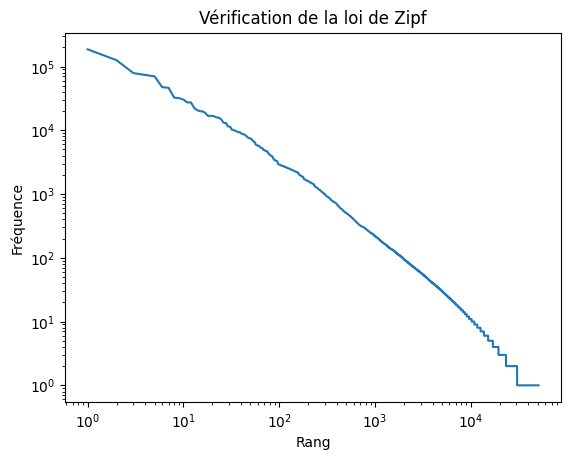

In [158]:
# on visualise le tout
import matplotlib.pyplot as plt

plt.figure()
plt.loglog(ranks, frequencies)
plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title("Vérification de la loi de Zipf")
plt.show()


Le graphique représentant la fréquence des mots en fonction de leur rang, en échelle logarithmique, montre une décroissance quasi linéaire. Cela signifie qu’un petit nombre de mots apparaît très fréquemment, tandis que la majorité des mots ont une fréquence faible, formant une longue traîne.

Cette distribution est conforme à la loi de Zipf, qui stipule que la fréquence d’un mot est inversement proportionnelle à son rang. La comparaison avec le graphique de validation montre une tendance similaire, bien que celui-ci soit légèrement plus lisse, ce qui peut s’expliquer par un corpus plus important ou un prétraitement plus poussé. Les écarts observés restent donc cohérents avec les limites d’un corpus de taille finie.

In [157]:
import matplotlib.pyplot as plt
#plot_zipf(tokens_counter)

## Validation avec un autre corpus : littérature anglaise

On compare avec la littérature anglaise, en utilisant pour simplifier le petit corpus littéraire anglais disponible dans `nltk`, qui comprend en effet non seulement du code (cf. supra, méthodes de segmentation et tokenisation), mais aussi beaucoup de ressources en anglais (cf. https://www.nltk.org/book/ch02.html)

**NB** l'anglais est privilégié dans la mesure où de nombreuses ressources pédagogiques ou à des fins de recherche sont disponibles prioritairement en anglais.

In [152]:
nltk.download('gutenberg')             # Run at first use only
from nltk.corpus import gutenberg

[nltk_data] Downloading package gutenberg to
[nltk_data]     /home/fatoumata/nltk_data...
[nltk_data]   Unzipping corpora/gutenberg.zip.


In [153]:
nltk.corpus.gutenberg.fileids()

['austen-emma.txt',
 'austen-persuasion.txt',
 'austen-sense.txt',
 'bible-kjv.txt',
 'blake-poems.txt',
 'bryant-stories.txt',
 'burgess-busterbrown.txt',
 'carroll-alice.txt',
 'chesterton-ball.txt',
 'chesterton-brown.txt',
 'chesterton-thursday.txt',
 'edgeworth-parents.txt',
 'melville-moby_dick.txt',
 'milton-paradise.txt',
 'shakespeare-caesar.txt',
 'shakespeare-hamlet.txt',
 'shakespeare-macbeth.txt',
 'whitman-leaves.txt']

In [154]:
tokenized_corpus = []
for text in gutenberg.fileids():
    tokenized_corpus.extend(gutenberg.words(text))

tokens_counter = Counter(tokenized_corpus)


In [ ]:
#plot_zipf(tokens_counter)

[186091, 125748, 78846, 73746, 70078, 47406, 46443, 32504, 31959, 30221, 27329, 27289, 22198, 20585, 19873, 19734, 18558, 16860, 16834, 16827, 16533, 15944, 15844, 15422, 14648, 13335, 12965, 12924, 11536, 11456, 11153, 10218, 10177, 9900, 9792, 9580, 9410, 9376, 9252, 8953, 8850, 8647, 8642, 8435, 8194, 8012, 7706, 7542, 7516, 7434, 7342, 7130, 6814, 6657, 6642, 6338, 5928, 5901, 5755, 5751, 5730, 5651, 5445, 5372, 5296, 5287, 5225, 4955, 4910, 4885, 4842, 4737, 4730, 4702, 4685, 4467, 4361, 4250, 4213, 4133, 4031, 3978, 3964, 3932, 3852, 3636, 3605, 3528, 3408, 3397, 3354, 3335, 3328, 3313, 3280, 3220, 2996, 2925, 2913, 2907, 2892, 2871, 2850, 2825, 2809, 2788, 2773, 2769, 2747, 2746, 2728, 2710, 2702, 2649, 2642, 2641, 2636, 2635, 2635, 2591, 2565, 2560, 2558, 2530, 2519, 2517, 2508, 2496, 2495, 2462, 2435, 2421, 2419, 2417, 2400, 2393, 2372, 2368, 2350, 2347, 2331, 2316, 2303, 2292, 2285, 2274, 2268, 2268, 2255, 2227, 2223, 2222, 2218, 2207, 2171, 2166, 2163, 2133, 2112, 2074, 2028

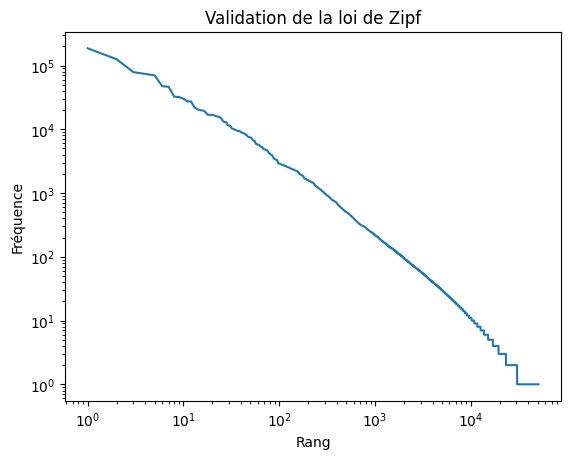

In [160]:
frequencies = sorted(tokens_counter.values(), reverse=True)
print(frequencies)
# on crée les range en partant de 1 jusqu'au nombre de tokens différents du plus fréquent
ranks = range(1, len(frequencies) + 1)
# on visualise le tout
import matplotlib.pyplot as plt

plt.figure()
plt.loglog(ranks, frequencies)
plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title("Validation de la loi de Zipf")
plt.show()